# 02 — Anomaly handling, validation scheme, preprocessing and baselines
This notebook covers the intermediate checkpoint: handling of data problems, the validation scheme with
the competition metric, preprocessing (encoding / scaling), a trivial baseline, trained models and
the first Kaggle submission.

In [1]:
import sys
sys.path.append("..")
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from src.data import (FIG_DIR, RANDOM_STATE, ROOT, SUB_DIR, TARGET, anomaly_report,
                      clean_train, load_data, rmse, rmsle)
from src.features import distance_features
from src.models import lgb_pipeline, linear_pipeline

SUB_DIR.mkdir(exist_ok=True)
train, test = load_data()
results = []          # every model scored on the same validation set goes here

def log_result(name, y_true_log, y_pred_log, note=""):
    score = rmse(y_true_log, y_pred_log)
    results.append({"model": name, "valid RMSLE": round(score, 5), "note": note})
    print(f"{name:<45s} RMSLE = {score:.5f}")
    # (no return value, so the notebook does not echo the number twice)

## 1. Validation scheme
* The test set is a **random** sample of the same Jan–Jun 2016 period (notebook 01), so a **random hold-out**
  reproduces the train/test relation: 80% of train for fitting, 20% for validation (≈ 292k trips — large
  enough that the score is stable to ~3 decimal places).
* The target is `log1p(trip_duration)`; RMSE on this scale equals the competition RMSLE.
  We also check this numerically with the `rmsle` function on the original scale.
* **No leakage:** the split is done *first*. Cleaning, scalers, encoders, PCA and clustering are fitted on the
  training part only (everything learned lives inside sklearn `Pipeline`s). The validation part is **never
  cleaned**, because the test set also contains the bad records and we must predict them too.
* For hyper-parameter tuning (notebook 03) a 3-fold CV inside the training part is used, so the hold-out
  stays untouched for the final comparison.

In [2]:
tr, va = train_test_split(train, test_size=0.2, random_state=RANDOM_STATE)
y_va = np.log1p(va[TARGET].to_numpy())
print(f"train part: {len(tr):,}   validation part: {len(va):,}")

train part: 1,166,915   validation part: 291,729


## 2. Missing values and anomalies: decision
There are **no missing values**, so nothing has to be filled. For the anomalies found in the EDA:

| problem | train part | validation / test | reason |
|---|---|---|---|
| duration > 6 h (meter left on) | **drop** | keep | not a real trip; on the log scale these points are ~4 units away from the rest and pull the model |
| passenger_count 0 or > 6 | **drop** | keep | impossible values, only 65 rows — no information lost |
| coordinates outside the NYC box | **drop** | keep + **flag** (`flag_outside_nyc`) | GPS errors; too few to learn from |
| duration < 60 s, zero distance | **keep** | keep | they also exist in test (0.4% zero-distance); the model must learn that they are short |

Test rows can never be dropped, so every row of validation and test still gets a prediction.
Below we check what the cleaning changes, always scoring on the (uncleaned) validation set.

In [3]:
tr_clean = clean_train(tr)
print(f"dropped from the training part: {len(tr) - len(tr_clean):,} rows ({100 * (1 - len(tr_clean) / len(tr)):.2f}%)")
anomaly_report(tr)

dropped from the training part: 2,468 rows (0.21%)


,count,share_%
pickup or dropoff outside NYC box,795,0.068
passenger_count == 0,47,0.004
passenger_count > 6,4,0.000
pickup == dropoff coordinates,4690,0.402
trip_duration > 6 h,1626,0.139
trip_duration < 60 s,6870,0.589


In [4]:
def fit_lgb(df, **kw):
    """LightGBM with fixed (untuned) parameters on all engineered features, see src/models.py."""
    return lgb_pipeline(**kw).fit(df, np.log1p(df[TARGET]))

from src.data import MAX_DURATION, inside_nyc
# "clean" subset of the validation part — used ONLY to understand the errors, never for model choice
va_good = ((va[TARGET] <= MAX_DURATION) & inside_nyc(va) & va["passenger_count"].between(1, 6)).to_numpy()
variants = {
    "no cleaning": tr,
    "drop > 6 h only": tr[tr[TARGET] <= MAX_DURATION],
    "drop impossible passengers / coords only": tr[tr["passenger_count"].between(1, 6) & inside_nyc(tr)],
    "full cleaning (clean_train)": tr_clean,
}
rows = []
for name, df in variants.items():
    pred = fit_lgb(df).predict(va)
    rows.append({"training data": name, "rows": len(df),
                 "RMSLE, full validation": round(rmse(y_va, pred), 5),
                 "RMSLE, validation without anomalies": round(rmse(y_va[va_good], pred[va_good]), 5)})
cleaning_table = pd.DataFrame(rows)
cleaning_table

,training data,rows,"RMSLE, full validation","RMSLE, validation without anomalies"
0,no cleaning,1166915,0.38431,0.33675
1,drop > 6 h only,1165289,0.38410,0.33630
2,drop impossible passengers / coords only,1166070,0.38432,0.33664
3,full cleaning (clean_train),1164447,0.38463,0.33664


In [5]:
err2 = (pred - y_va) ** 2
print(f"anomalous rows: {100 * (~va_good).mean():.2f}% of validation, "
      f"but {100 * err2[~va_good].sum() / err2.sum():.1f}% of the total squared error")

anomalous rows: 0.22% of validation, but 23.6% of the total squared error


**Result.**
* All cleaning variants score within ±0.0005 of each other on the full validation set — that is noise
  level, so cleaning the *training* data neither helps nor hurts measurably. We keep the full cleaning
  because the dropped rows are not real trips and LightGBM is robust to them either way.
* The important finding is in the last column: the **same model** scores ≈ 0.337 on validation once the
  0.2% anomalous trips are excluded, versus ≈ 0.384 on all trips. These few rows (mostly 24 h
  "meter left on" trips that look like ordinary 2 km rides) cause a large share of the total error,
  and they are **unpredictable from the features**. The test set has them too, so the leaderboard
  score has the same floor — that is why the validation score is always computed on the uncleaned part.
* Keeping short / zero-distance trips is deliberate: removing them would make the model blind to a pattern
  that appears in the test set.

## 3. Preprocessing
* **Binary categoricals** (`vendor_id`, `store_and_fwd_flag`) → 0/1. With two levels this is identical
  to one-hot encoding.
* **For the linear model:** `hour`, `weekday`, `month`, `passenger_count` and the coordinate clusters are
  **one-hot encoded** — their effect is not linear (e.g. hour 23 is not "23 times" hour 1). All numeric
  columns are **standardised**, because Ridge regularisation penalises coefficients and is
  therefore sensitive to the scale of the inputs.
* **For tree models** (random forest, LightGBM) no scaling and no one-hot is needed: splits are invariant
  to monotone transformations, and integer-coded categories such as `hour` can be split directly.
* All encoders / scalers are inside the pipeline → fitted on the training part only.

## 4. Baselines
### 4.1 Trivial prediction: a constant
For RMSLE the best constant is not the mean, but `expm1(mean(log1p(y)))` (the geometric mean),
because RMSLE is RMSE on the log scale and the mean minimises RMSE.

In [6]:
y_tr_log = np.log1p(tr_clean[TARGET])
const = y_tr_log.mean()
print(f"best constant: {np.expm1(const):.0f} s  (arithmetic mean would be {tr_clean[TARGET].mean():.0f} s)")
log_result("constant (geometric mean)", y_va, np.full(len(va), const), "trivial baseline")
log_result("constant (arithmetic mean)", y_va, np.full(len(va), np.log1p(tr_clean[TARGET].mean())), "shows why the log matters")
print("check on the original scale:", round(rmsle(va[TARGET], np.full(len(va), np.expm1(const))), 5))

best constant: 638 s  (arithmetic mean would be 836 s)
constant (geometric mean)                     RMSLE = 0.79665
constant (arithmetic mean)                    RMSLE = 0.83858
check on the original scale: 0.79665


### 4.2 Simple rule: duration from distance
A hand-made rule: split trips into 20 bins of straight-line distance and predict the
geometric-mean duration of the bin (bins and values computed on the training part).

In [7]:
d_tr = distance_features(tr_clean)["dist_haversine"]
d_va = distance_features(va)["dist_haversine"]
_, edges = pd.qcut(d_tr, 20, retbins=True, duplicates="drop")
edges[0], edges[-1] = -np.inf, np.inf
bin_mean = y_tr_log.groupby(pd.cut(d_tr, edges), observed=False).mean()
pred_rule = pd.cut(d_va, edges).map(bin_mean).astype(float).to_numpy()
log_result("rule: mean by distance bin", y_va, pred_rule, "20 quantile bins of haversine distance")

rule: mean by distance bin                    RMSLE = 0.51379


### 4.3 Trained models
* **Ridge regression** with the preprocessing above (linear model, `src/models.py: linear_pipeline`).
* **LightGBM on raw columns only** — the original 7 features, no engineering — to see what the
  feature engineering in notebook 03 adds.
* **LightGBM with all engineered features** (fixed, untuned parameters).

In [8]:
t = time.time()
ridge = linear_pipeline(alpha=1.0).fit(tr_clean, y_tr_log)
log_result("Ridge (one-hot + scaling, all features)", y_va, ridge.predict(va), f"alpha=1, {time.time() - t:.0f}s")

t = time.time()
lgb_raw = fit_lgb(tr_clean, groups=())
log_result("LightGBM, raw features only", y_va, lgb_raw.predict(va), f"400 trees, {time.time() - t:.0f}s")

t = time.time()
lgb_all = fit_lgb(tr_clean)
pred_lgb = lgb_all.predict(va)
log_result("LightGBM, all engineered features", y_va, pred_lgb, f"400 trees, {time.time() - t:.0f}s")

Ridge (one-hot + scaling, all features)       RMSLE = 0.46603


LightGBM, raw features only                   RMSLE = 0.46004


LightGBM, all engineered features             RMSLE = 0.38463


In [9]:
table = pd.DataFrame(results).sort_values("valid RMSLE", ascending=False).reset_index(drop=True)
table.to_csv(ROOT / "reports" / "results_02_baselines.csv", index=False)
table

,model,valid RMSLE,note
0,constant (arithmetic mean),0.83858,shows why the log matters
1,constant (geometric mean),0.79665,trivial baseline
2,rule: mean by distance bin,0.51379,20 quantile bins of haversine distance
3,"Ridge (one-hot + scaling, all features)",0.46603,"alpha=1, 20s"
4,"LightGBM, raw features only",0.46004,"400 trees, 18s"
5,"LightGBM, all engineered features",0.38463,"400 trees, 38s"


## 5. Where does the model make mistakes?

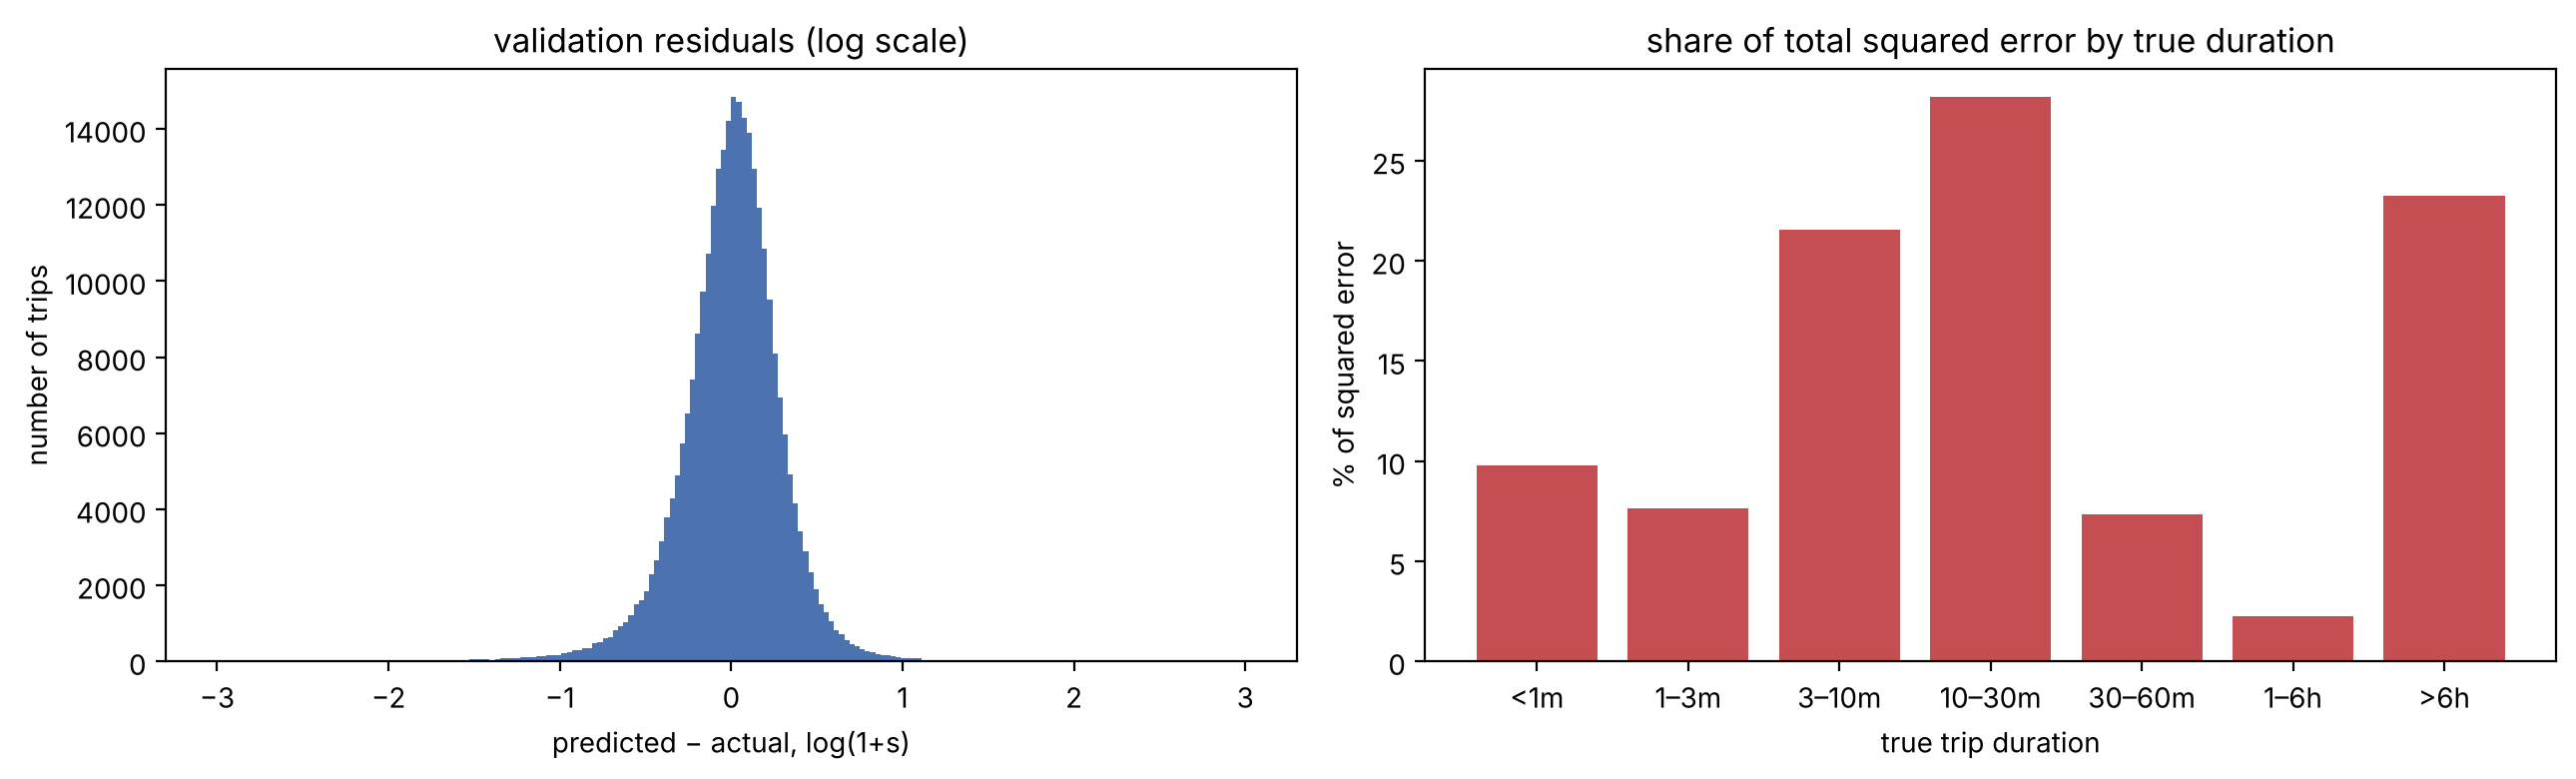

share of trips, %:         {'<1m': 0.6, '1–3m': 4.41, '3–10m': 39.68, '10–30m': 47.49, '30–60m': 6.97, '1–6h': 0.7, '>6h': 0.15}
share of squared error, %: {'<1m': 9.8, '1–3m': 7.6, '3–10m': 21.6, '10–30m': 28.2, '30–60m': 7.4, '1–6h': 2.3, '>6h': 23.2}


In [10]:
err = pred_lgb - y_va
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(err, bins=200, range=(-3, 3), color="#4C72B0")
axes[0].set(title="validation residuals (log scale)", xlabel="predicted − actual, log(1+s)", ylabel="number of trips")
bins = pd.cut(va[TARGET], [0, 60, 180, 600, 1800, 3600, 6 * 3600, np.inf],
              labels=["<1m", "1–3m", "3–10m", "10–30m", "30–60m", "1–6h", ">6h"])
contrib = pd.Series(err ** 2, index=va.index).groupby(bins, observed=False).sum() / (err ** 2).sum() * 100
axes[1].bar(contrib.index.astype(str), contrib.values, color="#C44E52")
axes[1].set(title="share of total squared error by true duration", xlabel="true trip duration", ylabel="% of squared error")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_residuals.png", dpi=150, bbox_inches="tight")
plt.show()
print("share of trips, %:        ", (bins.value_counts(normalize=True).sort_index() * 100).round(2).to_dict())
print("share of squared error, %:", contrib.round(1).to_dict())

**Findings.** Residuals are centred at 0 and roughly symmetric on the log scale. The error is very unevenly
distributed: trips longer than 6 h are ~0.15% of the validation set but cause ~23% of the squared error, and
trips shorter than 1 minute (~0.6%) cause ~10%. Both groups are mostly recording errors (meter left on,
cancelled trip) that the features cannot reveal. Improving typical 3–30 minute trips is where modelling
can still gain; the anomalies set a floor on the achievable score.

## 6. First Kaggle submission
Re-fit the LightGBM pipeline on the **whole cleaned train set** and predict the test set.

In [11]:
full_clean = clean_train(train)
final = fit_lgb(full_clean)
sub = pd.DataFrame({"id": test["id"], TARGET: np.expm1(final.predict(test)).clip(1, None)})
path = SUB_DIR / "02_lightgbm_untuned.csv"
sub.to_csv(path, index=False)
print(path, sub.shape)
sub.head()

/home/claude/nyc-taxi-trip-duration/submissions/02_lightgbm_untuned.csv (625134, 2)


,id,trip_duration
0,id3004672,809.564107
1,id3505355,627.503331
2,id1217141,416.952154
3,id2150126,916.653948
4,id1598245,360.226041
